# U2 · Dimensión Estaciones — 01. Modelo de series de tiempo por estación (batch)

**Integrante:** Grimaldo Arredondo Martinez — Data Geniuses · **Proyecto Sello:** CitiBike Intelligent Mobility

**Pregunta U2 (Brief S2, diapositiva 12):** *¿Qué estaciones podrían registrar mayor demanda durante la siguiente ventana temporal?*

**Evolución desde U1.** En U1 (`UNIDAD1/Dim-Estaciones/utilizacion_estaciones.ipynb`) la pregunta era *qué estaciones* tienen alta demanda en un **día** (clasificación, RandomForest, AUC 0.786). En U2 la pregunta pasa a **cuántos viajes saldrán de cada estación en los próximos 15 minutos**, que es lo que necesita una operación en vivo. Es la segunda mitad de CE043-N3: una serie de tiempo que se reutiliza para inferencia sobre el flujo (notebook 02).

| Decisión | U1 | U2 (este notebook) |
|---|---|---|
| Granularidad | estación × día | estación × ventana de 15 min |
| Objetivo | `es_alta_demanda` (P75) | `salidas` en la ventana t+1 |
| Modelo | clasificación | regresión sobre la serie (lags + estacionalidad) |
| Estaciones | todas | **top-K** por volumen (Brief: "según viabilidad computacional") |
| Corte train/test | primeros 75 % de los días | **el mismo corte** (2026-07-24) |

## 1. SparkSession

Zona horaria `America/New_York`, igual que U1: los CSV vienen en hora local de NYC y la hora del día es una variable del modelo. El notebook 02 usa la misma zona; si no, la hora de las features no coincidiría entre entrenamiento e inferencia.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = (
    SparkSession.builder
    .appName("U2_Estaciones_01_SeriesTiempo_GrimaldoArredondo")
    .master("local[*]")
    .config("spark.driver.memory", "5g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.session.timeZone", "America/New_York")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/30 02:52:55 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0


In [2]:
import json, os

DATA_PATH = "./data/*.csv"          # los mismos 5 CSV de U1 (copiarlos a esta carpeta)
ARTIFACTS = "./artifacts"
VENTANA_MIN = 15                    # tamaño de la ventana de la serie (igual que en streaming)
TOP_K = 20                          # estaciones que se modelan y se siguen en vivo
os.makedirs(ARTIFACTS, exist_ok=True)

## 2. Bronze → Silver (mismas reglas de U1)

Esquema explícito: los IDs de estación (`6140.05`) se leen como `String`. Si se infiere el tipo pasan a `double` y `6364.10` se convierte en `6364.1`. Silver aplica las reglas comunes del equipo: deduplicar por `ride_id`, descartar estaciones nulas y quedarse con duraciones entre 1 y 180 minutos.

In [3]:
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, TimestampType

esquema_viajes = StructType([
    StructField("ride_id", StringType()), StructField("rideable_type", StringType()),
    StructField("started_at", TimestampType()), StructField("ended_at", TimestampType()),
    StructField("start_station_name", StringType()), StructField("start_station_id", StringType()),
    StructField("end_station_name", StringType()), StructField("end_station_id", StringType()),
    StructField("start_lat", DoubleType()), StructField("start_lng", DoubleType()),
    StructField("end_lat", DoubleType()), StructField("end_lng", DoubleType()),
    StructField("member_casual", StringType()),
])

bronze = (spark.read.option("header", True)
          .option("timestampFormat", "yyyy-MM-dd HH:mm:ss[.SSS]")
          .schema(esquema_viajes).csv(DATA_PATH))

duracion = (F.unix_timestamp("ended_at") - F.unix_timestamp("started_at")) / 60.0
silver = (bronze.dropDuplicates(["ride_id"])
          .na.drop(subset=["start_station_id", "end_station_id", "started_at", "ended_at"])
          .filter(duracion.between(1.0, 180.0))
          .cache())

n_bronze, n_silver = bronze.count(), silver.count()
print(f"Bronze: {n_bronze:,}  ->  Silver: {n_silver:,}  ({n_bronze - n_silver:,} descartados por calidad)")

Bronze: 4,993,137  ->  Silver: 4,971,847  (21,290 descartados por calidad)


## 3. Corte temporal (el mismo de U1)

Se repite exactamente la regla de U1: el corte cae en `desde + int(días × 0.75)`. Todo lo que el modelo aprende (incluida la media histórica por franja) sale solo de las fechas de entrenamiento. El productor `producer_rides_replay.py` reproduce un día **posterior** al corte (por defecto, 2026-07-28), así que la inferencia en vivo corre sobre datos que el modelo nunca vio.

In [4]:
import datetime as dt

rango = silver.agg(F.min(F.to_date("started_at")).alias("desde"), F.max(F.to_date("started_at")).alias("hasta")).first()
desde, hasta = rango["desde"], rango["hasta"]
dias = (hasta - desde).days + 1
CORTE = desde + dt.timedelta(days=int(dias * 0.75))
print(f"Rango: {desde} -> {hasta} ({dias} días) | corte train/test: {CORTE}")

Rango: 2026-06-30 -> 2026-07-31 (32 días) | corte train/test: 2026-07-24


## 4. Estaciones top-K

Modelar las ~2.000 estaciones por separado no escala (Brief, nota de la diapositiva 12). Se eligen las **K = 20** con más salidas **en el período de entrenamiento** y se entrena un único modelo **global** para todas. La identidad de cada estación entra al modelo a través de su media histórica por franja (sección 5). El archivo `estaciones_top.json` es el contrato con los productores: `producer_gbfs_estaciones.py` sigue estas mismas estaciones en el feed en vivo.

In [5]:
train_viajes = silver.filter(F.to_date("started_at") < F.lit(CORTE))

top = (train_viajes.groupBy("start_station_id")
       .agg(F.count("*").alias("viajes_train"),
            F.first("start_station_name").alias("station_name"),
            F.round(F.avg("start_lat"), 6).alias("lat"), F.round(F.avg("start_lng"), 6).alias("lng"))
       .orderBy(F.desc("viajes_train")).limit(TOP_K)
       .withColumnRenamed("start_station_id", "station_id"))
top_pd = top.toPandas()
top_pd

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,station_id,viajes_train,station_name,lat,lng
0,6233.04,13072,Pier 61 at Chelsea Piers,40.746872,-74.008210
1,6140.05,12029,W 21 St & 6 Ave,40.741740,-73.994156
2,5712.03,11575,Cooper Square & Astor Pl,40.729515,-73.990753
3,6492.08,10805,9 Ave & W 33 St,40.752568,-73.996765
4,6331.01,10777,W 31 St & 7 Ave,40.749156,-73.991600
5,5905.12,10756,Broadway & E 14 St,40.734546,-73.990741
6,6912.01,10193,7 Ave & Central Park South,40.766741,-73.979069
7,6948.10,10159,Broadway & W 58 St,40.766953,-73.981693
8,5980.10,10047,E 17 St & Broadway,40.737006,-73.990134
9,6876.04,10025,Central Park S & 6 Ave,40.765909,-73.976342


In [6]:
total_train = train_viajes.count()
with open(f"{ARTIFACTS}/estaciones_top.json", "w", encoding="utf-8") as f:
    json.dump({
        "generado": dt.datetime.now().isoformat(timespec="seconds"),
        "criterio": f"top {TOP_K} por salidas en train (< {CORTE})",
        "participacion_pct": round(100 * top_pd["viajes_train"].sum() / total_train, 2),
        "estaciones": top_pd.to_dict(orient="records"),
    }, f, ensure_ascii=False, indent=2)
print(f"Las {TOP_K} estaciones concentran el {100 * top_pd['viajes_train'].sum() / total_train:.2f} % de las salidas de train")

Las 20 estaciones concentran el 5.65 % de las salidas de train


## 5. Serie estación × ventana de 15 min, con ceros explícitos

`groupBy(window(...))` solo genera filas para las ventanas que tuvieron viajes. Una ventana sin salidas es un **0** real, no un dato faltante. Por eso se arma la malla completa (todas las ventanas × todas las estaciones top) y se completa con 0. Si no se hace, los lags "saltan" sobre los huecos y el modelo aprende una serie que no existe.

In [7]:
ids_top = [r["station_id"] for r in top.select("station_id").collect()]
viajes_top = silver.filter(F.col("start_station_id").isin(ids_top) | F.col("end_station_id").isin(ids_top))
ventana = f"{VENTANA_MIN} minutes"

salidas = (viajes_top.filter(F.col("start_station_id").isin(ids_top))
           .groupBy(F.col("start_station_id").alias("station_id"), F.window("started_at", ventana).start.alias("slot"))
           .agg(F.count("*").alias("salidas")))
llegadas = (viajes_top.filter(F.col("end_station_id").isin(ids_top))
            .groupBy(F.col("end_station_id").alias("station_id"), F.window("ended_at", ventana).start.alias("slot"))
            .agg(F.count("*").alias("llegadas")))

# La malla se arma dentro de Spark (sin pasar timestamps por Python, que los mostraría en la zona del contenedor)
malla = (salidas.agg(F.min("slot").alias("a"), F.max("slot").alias("b"))
         .select(F.explode(F.sequence("a", "b", F.expr(f"INTERVAL {VENTANA_MIN} MINUTES"))).alias("slot"))
         .crossJoin(top.select("station_id")))

serie = (malla.join(salidas, ["station_id", "slot"], "left")
              .join(llegadas, ["station_id", "slot"], "left")
              .na.fill(0, ["salidas", "llegadas"])
              .cache())
print(f"Filas de la serie: {serie.count():,} = {serie.select('slot').distinct().count():,} ventanas × {len(ids_top)} estaciones")
serie.orderBy("station_id", "slot").show(5)

Filas de la serie: 59,580 = 2,979 ventanas × 20 estaciones


+----------+-------------------+-------+--------+
|station_id|               slot|salidas|llegadas|
+----------+-------------------+-------+--------+
|   5492.05|2026-06-30 23:15:00|      0|       0|
|   5492.05|2026-06-30 23:30:00|      0|       0|
|   5492.05|2026-06-30 23:45:00|      0|       0|
|   5492.05|2026-07-01 00:00:00|      8|       0|
|   5492.05|2026-07-01 00:15:00|      2|       1|
+----------+-------------------+-------+--------+
only showing top 5 rows


## 6. Features y objetivo

Cada fila representa el momento en que **se cierra la ventana t**: con lo observado hasta ahí se predicen las salidas de la ventana **t+1**. Es exactamente la información que el notebook 02 tiene disponible en vivo.

| Feature | Qué es |
|---|---|
| `s_t`, `s_t1`, `s_t2`, `s_t3` | salidas en t, t-1, t-2, t-3 (la última hora) |
| `l_t` | llegadas en t (bicis que entraron a la estación) |
| `hora_sin`, `hora_cos` | hora del día de la ventana objetivo, en forma cíclica (23 h queda junto a 0 h) |
| `finde_obj` | la ventana objetivo cae en sábado o domingo |
| `media_slot_obj` | media histórica de salidas de **esa estación**, en esa franja horaria y tipo de día (**solo con datos de train**) |
| `label` | salidas en t+1 |

In [8]:
w = Window.partitionBy("station_id").orderBy("slot")
base = (serie
        .withColumn("s_t", F.col("salidas"))
        .withColumn("s_t1", F.lag("salidas", 1).over(w))
        .withColumn("s_t2", F.lag("salidas", 2).over(w))
        .withColumn("s_t3", F.lag("salidas", 3).over(w))
        .withColumn("l_t", F.col("llegadas"))
        .withColumn("label", F.lead("salidas", 1).over(w))
        .withColumn("slot_obj", F.col("slot") + F.expr(f"INTERVAL {VENTANA_MIN} MINUTES"))
        .withColumn("hora_obj", F.hour("slot_obj") + F.minute("slot_obj") / 60.0)
        .withColumn("finde_obj", F.dayofweek("slot_obj").isin(1, 7).cast("int"))
        .withColumn("hora_slot_obj", F.hour("slot_obj"))
        .na.drop(subset=["s_t1", "s_t2", "s_t3", "label"]))

# Media histórica por (estación, tipo de día, hora): SOLO con el período de entrenamiento
media_slot = (serie.filter(F.to_date("slot") < F.lit(CORTE))
              .withColumn("finde", F.dayofweek("slot").isin(1, 7).cast("int"))
              .groupBy("station_id", "finde", F.hour("slot").alias("hora"))
              .agg(F.round(F.avg("salidas"), 4).alias("media_slot")))

dataset = (base.join(media_slot.withColumnRenamed("finde", "finde_obj").withColumnRenamed("hora", "hora_slot_obj")
                     .withColumnRenamed("media_slot", "media_slot_obj"),
                     ["station_id", "finde_obj", "hora_slot_obj"], "left")
               .na.fill(0.0, ["media_slot_obj"])
               .withColumn("hora_sin", F.sin(2 * 3.141592653589793 * F.col("hora_obj") / 24))
               .withColumn("hora_cos", F.cos(2 * 3.141592653589793 * F.col("hora_obj") / 24))
               .withColumn("label", F.col("label").cast("double")))

FEATURES = ["s_t", "s_t1", "s_t2", "s_t3", "l_t", "hora_sin", "hora_cos", "finde_obj", "media_slot_obj"]

train = dataset.filter(F.to_date("slot_obj") < F.lit(CORTE)).cache()
test = dataset.filter(F.to_date("slot_obj") >= F.lit(CORTE)).cache()
lim = (train.agg(F.max("slot_obj").alias("m")).crossJoin(test.agg(F.min("slot_obj").alias("n")))
       .select((F.col("m") < F.col("n")).alias("ok"), F.date_format("m", "yyyy-MM-dd HH:mm").alias("m"),
               F.date_format("n", "yyyy-MM-dd HH:mm").alias("n")).first())
assert lim["ok"], "El split no respeta el orden temporal"
print(f"Train: {train.count():,} filas (ventana objetivo hasta {lim['m']}) | Test: {test.count():,} filas (desde {lim['n']}, hora NYC)")

Train: 44,140 filas (ventana objetivo hasta 2026-07-23 23:45) | Test: 15,360 filas (desde 2026-07-24 00:00, hora NYC)


## 7. Baselines antes de entrenar

Un modelo de series de tiempo solo vale la pena si le gana a dos reglas triviales:
- **Persistencia:** "en los próximos 15 min saldrán tantas bicis como en los últimos 15".
- **Media histórica:** "saldrá lo que sale en promedio de esta estación a esta hora".

In [9]:
from pyspark.ml.evaluation import RegressionEvaluator

ev = {m: RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName=m) for m in ("rmse", "mae", "r2")}

def evaluar(pred, nombre):
    r = {"modelo": nombre, **{m.upper(): round(e.evaluate(pred), 4) for m, e in ev.items()}}
    print(f"{nombre:32s} RMSE={r['RMSE']:.4f}  MAE={r['MAE']:.4f}  R2={r['R2']:.4f}")
    return r

resultados = [
    evaluar(test.withColumn("prediction", F.col("s_t").cast("double")), "Baseline persistencia"),
    evaluar(test.withColumn("prediction", F.col("media_slot_obj")), "Baseline media histórica"),
]

Baseline persistencia            RMSE=3.7468  MAE=2.4977  R2=0.4503


Baseline media histórica         RMSE=3.1973  MAE=2.1231  R2=0.5997


## 8. Modelos distribuidos (Spark MLlib)

In [10]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, GBTRegressor

def pipeline(estimador):
    return Pipeline(stages=[VectorAssembler(inputCols=FEATURES, outputCol="features"), estimador])

candidatos = {
    "LinearRegression": pipeline(LinearRegression(labelCol="label")),
    "GBTRegressor (60 árboles)": pipeline(GBTRegressor(labelCol="label", maxIter=60, maxDepth=5, seed=42)),
}
modelos = {}
for nombre, p in candidatos.items():
    modelos[nombre] = p.fit(train)
    resultados.append(evaluar(modelos[nombre].transform(test), nombre))

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


LinearRegression                 RMSE=2.9492  MAE=1.9805  R2=0.6594


GBTRegressor (60 árboles)        RMSE=2.9576  MAE=1.9845  R2=0.6575


In [11]:
import pandas as pd

tabla = pd.DataFrame(resultados)
rmse_pers = tabla.loc[tabla.modelo == "Baseline persistencia", "RMSE"].iloc[0]
tabla["mejora_RMSE_vs_persistencia_%"] = (100 * (rmse_pers - tabla["RMSE"]) / rmse_pers).round(2)
tabla

,modelo,RMSE,MAE,R2,mejora_RMSE_vs_persistencia_%
0,Baseline persistencia,3.7468,2.4977,0.4503,0.00
1,Baseline media histórica,3.1973,2.1231,0.5997,14.67
2,LinearRegression,2.9492,1.9805,0.6594,21.29
3,GBTRegressor (60 árboles),2.9576,1.9845,0.6575,21.06


## 9. Selección, persistencia y verificación

Se guarda el `PipelineModel` completo (`VectorAssembler` + modelo) del candidato con menor RMSE en test. El notebook 02 lo carga tal cual. También se guarda la tabla `media_slot`, que es una feature, para que la inferencia en vivo use exactamente la misma.

In [12]:
from pyspark.ml import PipelineModel

entrenados = tabla[tabla.modelo.isin(list(modelos))]
ganador = entrenados.sort_values("RMSE").iloc[0]
print("Modelo ganador:", ganador["modelo"], "| RMSE", ganador["RMSE"], "| MAE", ganador["MAE"], "| R2", ganador["R2"])

RUTA_MODELO = f"{ARTIFACTS}/models/modelo_estaciones_ts"
modelos[ganador["modelo"]].write().overwrite().save(RUTA_MODELO)
media_slot.write.mode("overwrite").parquet(f"{ARTIFACTS}/media_slot")

recargado = PipelineModel.load(RUTA_MODELO)
rmse_recargado = ev["rmse"].evaluate(recargado.transform(test))
print(f"RMSE del modelo recargado: {rmse_recargado:.4f} (esperado {ganador['RMSE']}) -> coincide: {round(rmse_recargado, 4) == ganador['RMSE']}")

with open(f"{ARTIFACTS}/metricas_modelo.json", "w", encoding="utf-8") as f:
    json.dump({"ventana_min": VENTANA_MIN, "top_k": TOP_K, "corte": str(CORTE), "features": FEATURES,
               "ganador": ganador["modelo"], "resultados": resultados}, f, ensure_ascii=False, indent=2)

Modelo ganador: LinearRegression | RMSE 2.9492 | MAE 1.9805 | R2 0.6594


RMSE del modelo recargado: 2.9492 (esperado 2.9492) -> coincide: True


## 10. Error por estación (¿dónde falla el modelo?)

In [13]:
pred_test = recargado.transform(test)
(pred_test.groupBy("station_id")
 .agg(F.round(F.avg(F.abs(F.col("prediction") - F.col("label"))), 3).alias("MAE"),
      F.round(F.avg("label"), 2).alias("salidas_medias"))
 .withColumn("MAE_relativo", F.round(F.col("MAE") / F.col("salidas_medias"), 3))
 .join(top.select("station_id", "station_name"), "station_id")
 .orderBy(F.desc("MAE")).show(TOP_K, truncate=False))

+----------+-----+--------------+------------+--------------------------+
|station_id|MAE  |salidas_medias|MAE_relativo|station_name              |
+----------+-----+--------------+------------+--------------------------+
|6233.04   |2.326|6.69          |0.348       |Pier 61 at Chelsea Piers  |
|6876.04   |2.281|5.38          |0.424       |Central Park S & 6 Ave    |
|6492.08   |2.253|5.21          |0.432       |9 Ave & W 33 St           |
|6331.01   |2.151|5.12          |0.42        |W 31 St & 7 Ave           |
|6157.04   |2.131|4.8           |0.444       |10 Ave & W 14 St          |
|6912.01   |2.08 |4.9           |0.424       |7 Ave & Central Park South|
|6140.05   |2.068|6.07          |0.341       |W 21 St & 6 Ave           |
|5712.03   |2.025|5.36          |0.378       |Cooper Square & Astor Pl  |
|6948.10   |2.013|4.93          |0.408       |Broadway & W 58 St        |
|6432.09   |2.001|4.55          |0.44        |Park Ave & E 42 St        |
|6726.01   |1.942|4.77          |0.407

## 11. Publicar las métricas del modelo en Grafana (Pushgateway)

El panel "Modelo" del tablero muestra el RMSE/MAE/R² de test junto al MAE **en producción** que calcula el notebook 02. Si Pushgateway no está levantado, la celda solo avisa.

In [14]:
import urllib.request

def push(job, cuerpo, instancia="batch"):
    url = f"http://pushgateway:9091/metrics/job/{job}/instance/{instancia}"
    req = urllib.request.Request(url, data=cuerpo.encode(), method="PUT")
    with urllib.request.urlopen(req, timeout=5) as r:
        return r.status

lineas = []
for r in resultados:
    etiqueta = r["modelo"].replace('"', "")
    for m in ("RMSE", "MAE", "R2"):
        lineas.append(f'lambda26_u2est_modelo_{m.lower()}_test{{modelo="{etiqueta}"}} {r[m]}')
lineas.append(f'lambda26_u2est_modelo_ganador_info{{modelo="{ganador["modelo"]}"}} 1')
try:
    print("Pushgateway:", push("lambda26_u2_estaciones_modelo", "\n".join(lineas) + "\n"))
except Exception as ex:
    print("Pushgateway no disponible (no es error del modelo):", ex)

Pushgateway: 200


## 12. Real vs. predicho en test, para la estación con más demanda


[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


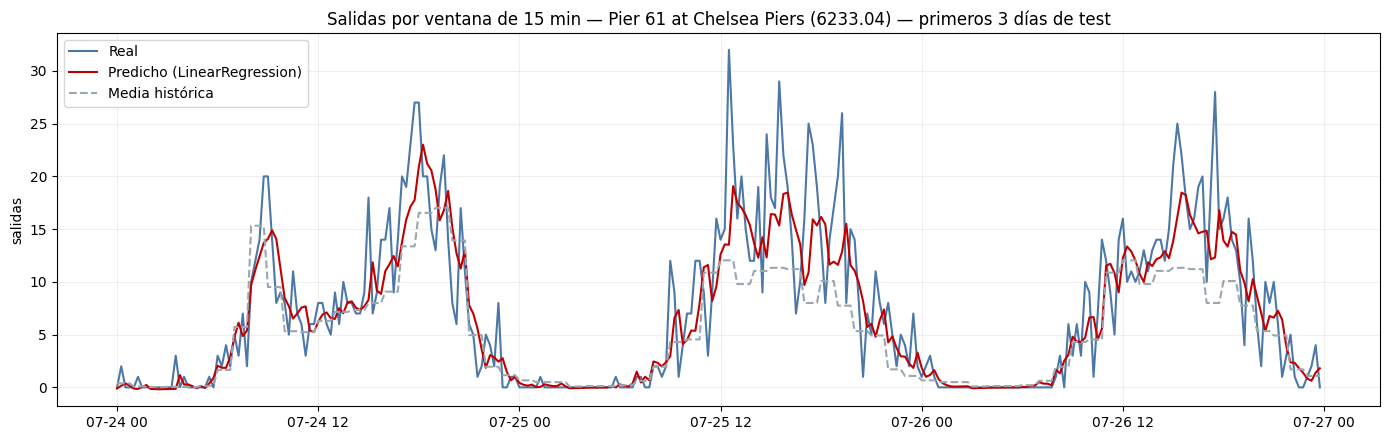

In [15]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib"], check=True)
    import matplotlib.pyplot as plt

est = ids_top[0]
nombre_est = top_pd.loc[top_pd.station_id == est, "station_name"].iloc[0]
g = (pred_test.filter(F.col("station_id") == est).orderBy("slot_obj")
     .select("slot_obj", "label", "prediction", "media_slot_obj").limit(4 * 24 * 3).toPandas())
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(g.slot_obj, g.label, label="Real", color="#4C78A8")
ax.plot(g.slot_obj, g.prediction, label=f"Predicho ({ganador['modelo']})", color="#C00000")
ax.plot(g.slot_obj, g.media_slot_obj, label="Media histórica", color="#9AA7B0", linestyle="--")
ax.set_title(f"Salidas por ventana de {VENTANA_MIN} min — {nombre_est} ({est}) — primeros 3 días de test")
ax.set_ylabel("salidas"); ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout(); plt.savefig(f"{ARTIFACTS}/real_vs_predicho.png", dpi=120); plt.show()

## 13. Síntesis para la sustentación

1. **Una pregunta nueva sobre los mismos datos:** U1 clasificaba días de alta demanda; U2 pronostica salidas cada 15 min, que es lo accionable en vivo.
2. **Ceros explícitos:** sin la malla completa, los lags saltan sobre los huecos y la serie que aprende el modelo no existe.
3. **Sin fuga de información:** el corte es el mismo de U1, `media_slot` y el top-K salen solo de train, y el día que se reproduce en vivo es posterior al corte.
4. **Comparado contra baselines:** el modelo se justifica solo por lo que mejora frente a la persistencia y a la media histórica (tabla de la sección 8).
5. **Escalable:** un modelo global para K estaciones en lugar de K modelos. Pasar de 20 a 200 estaciones multiplica las filas, no la cantidad de modelos.